# 06_OULAD_Profils_Abandon.ipynb — CLUSTERING PROFILS TYPES

In [23]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# 1. SETUP

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import warnings
import os
import joblib
warnings.filterwarnings('ignore')

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import shap

base_path      = '/content/drive/MyDrive/MOOC_Recommandation_Adaptative/data/raw/OULAD'
processed_path = f"{base_path}/processed"
results_dir    = '/content/drive/MyDrive/MOOC_Recommandation_Adaptative/results'
metrics_dir    = f"{results_dir}/metrics"
plots_dir      = f"{results_dir}/plots"
profiles_dir   = f"{results_dir}/profiles"

os.makedirs(profiles_dir, exist_ok=True)

BEST_CUTOFF  = 42
RANDOM_STATE = 42

print("Setup terminé.")

Setup terminé.


# 2. CHARGEMENT

In [25]:
print("\n" + "="*70)
print("  CHARGEMENT DES DONNÉES")
print("="*70)

xgb_model = joblib.load(f"{results_dir}/models/xgboost_final_cutoff{BEST_CUTOFF}.joblib")
df        = pd.read_csv(f"{processed_path}/oulad_features_cutoff_{BEST_CUTOFF}.csv")
df_scores = pd.read_csv(f"{processed_path}/dropout_scores_cutoff{BEST_CUTOFF}.csv")

# Merge scores
df = pd.merge(df, df_scores[['id_student','code_module',
              'code_presentation','dropout_score']],
              on=['id_student','code_module','code_presentation'], how='left')

print(f"  Étudiants chargés : {len(df)}")
print(f"  Avec dropout score : {df['dropout_score'].notna().sum()}")


  CHARGEMENT DES DONNÉES
  Étudiants chargés : 32593
  Avec dropout score : 32593


# 3. PRÉPARATION FEATURES POUR CLUSTERING

In [26]:
print("\n" + "="*70)
print("  PRÉPARATION FEATURES POUR CLUSTERING")
print("="*70)

# Préparer X pour SHAP (identique notebook 03)
drop_cols = ['id_student', 'final_result', 'is_withdrawn',
             'cutoff_day', 'dropout_score']
cat_cols  = [c for c in df.select_dtypes(include='object').columns
             if c not in drop_cols]
df_enc    = pd.get_dummies(df, columns=cat_cols, drop_first=True)

num_cols = df_enc.select_dtypes(include=np.number).columns
for col in num_cols:
    df_enc[col] = df_enc[col].fillna(df_enc[col].median())

X_full = df_enc.drop(columns=drop_cols, errors='ignore')
X_full.columns = (X_full.columns
    .str.replace('[','',regex=False).str.replace(']','',regex=False)
    .str.replace('<','',regex=False).str.replace(' ','_',regex=False)
    .str.replace('-','_',regex=False))

expected = xgb_model.get_booster().feature_names
for col in expected:
    if col not in X_full.columns:
        X_full[col] = 0
X_full = X_full[[c for c in expected if c in X_full.columns]]

print(f"  Features préparées : {X_full.shape}")

# Focus sur étudiants à risque élevé (dropout_score > 0.5)
risk_mask    = df['dropout_score'] > 0.5
df_risk      = df[risk_mask].copy().reset_index(drop=True)
X_risk       = X_full[risk_mask].reset_index(drop=True)

print(f"  Étudiants à risque (score > 0.5) : {len(df_risk)} ({100*len(df_risk)/len(df):.1f}%)")


  PRÉPARATION FEATURES POUR CLUSTERING
  Features préparées : (32593, 69)
  Étudiants à risque (score > 0.5) : 10411 (31.9%)


# 4. CALCUL DES VALEURS SHAP POUR ÉTUDIANTS À RISQUE

In [27]:
print("\n" + "="*70)
print("  CALCUL SHAP — ÉTUDIANTS À RISQUE")
print("="*70)

# Échantillon pour performance
sample_size = min(3000, len(X_risk))
np.random.seed(RANDOM_STATE)
idx_sample  = np.random.choice(len(X_risk), sample_size, replace=False)
X_shap      = X_risk.iloc[idx_sample]
df_shap     = df_risk.iloc[idx_sample].copy()

explainer   = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_shap)

print(f"  SHAP calculé sur {sample_size} étudiants à risque")
print(f"  Shape SHAP values : {shap_values.shape}")

# Top features par importance SHAP
feat_importance = pd.DataFrame({
    'feature'   : X_shap.columns,
    'importance': np.abs(shap_values).mean(0)
}).sort_values('importance', ascending=False)

top_features = feat_importance.head(10)['feature'].tolist()
print(f"\n  Top 10 features SHAP : {top_features}")


  CALCUL SHAP — ÉTUDIANTS À RISQUE
  SHAP calculé sur 3000 étudiants à risque
  Shape SHAP values : (3000, 69)

  Top 10 features SHAP : ['last_activity_day', 'studied_credits', 'code_module_CCC', 'total_span_days', 'code_module_GGG', 'avg_score', 'code_module_BBB', 'num_submitted_assessments', 'code_presentation_2014J', 'TMA']


# 5. DÉTERMINATION DU NOMBRE OPTIMAL DE CLUSTERS

In [28]:
print("\n" + "="*70)
print("  DÉTERMINATION DU NOMBRE DE CLUSTERS")
print("="*70)

# Utiliser les valeurs SHAP des top features pour le clustering
# (les SHAP values capturent l'impact de chaque feature sur la prédiction)
shap_df = pd.DataFrame(shap_values, columns=X_shap.columns)
shap_top = shap_df[top_features].values

# Normalisation
scaler     = StandardScaler()
shap_scaled = scaler.fit_transform(shap_top)

# Méthode Elbow + Silhouette
inertias    = []
silhouettes = []
K_range     = range(2, 8)

print(f"\n  {'K':<6} {'Inertie':<15} {'Silhouette'}")
print("  " + "-"*35)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = kmeans.fit_predict(shap_scaled)
    inertias.append(kmeans.inertia_)
    sil = silhouette_score(shap_scaled, labels)
    silhouettes.append(sil)
    print(f"  {k:<6} {kmeans.inertia_:<15.1f} {sil:.4f}")

# Sélection automatique : meilleur silhouette
best_k = K_range[np.argmax(silhouettes)]
print(f"\n  Nombre optimal de clusters : K={best_k} "
      f"(Silhouette={max(silhouettes):.4f})")


  DÉTERMINATION DU NOMBRE DE CLUSTERS

  K      Inertie         Silhouette
  -----------------------------------
  2      24286.4         0.2209
  3      21212.8         0.2099
  4      19037.6         0.2282
  5      16191.4         0.2250
  6      14114.6         0.2428
  7      12436.5         0.2767

  Nombre optimal de clusters : K=7 (Silhouette=0.2767)


# 6. CLUSTERING FINAL

In [29]:
print("\n" + "="*70)
print(f"  CLUSTERING FINAL — K={best_k}")
print("="*70)

kmeans_final = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=20)
cluster_labels = kmeans_final.fit_predict(shap_scaled)

df_shap['cluster']        = cluster_labels
df_shap['dropout_score']  = df_shap['dropout_score'].values

# Ajouter features originales clés pour description
key_features_orig = ['total_clicks', 'total_days_active', 'avg_clicks_per_day',
                     'last_activity_day', 'total_span_days', 'avg_score',
                     'num_submitted_assessments', 'studied_credits']

for feat in key_features_orig:
    if feat in df_shap.columns:
        pass
    elif feat in df.columns:
        df_shap[feat] = df.loc[df_shap.index, feat].values \
                        if feat in df.columns else np.nan


  CLUSTERING FINAL — K=7


# 7. DESCRIPTION ET NOMMAGE DES PROFILS

In [30]:
print("\n" + "="*70)
print("  DESCRIPTION DES PROFILS")
print("="*70)

cluster_stats = []

for c in range(best_k):
    mask   = df_shap['cluster'] == c
    subset = df_shap[mask]
    n      = mask.sum()

    stats = {
        'cluster'               : c,
        'n'                     : n,
        'pct'                   : 100 * n / len(df_shap),
        'dropout_score_mean'    : subset['dropout_score'].mean(),
        'dropout_score_std'     : subset['dropout_score'].std(),
    }

    for feat in key_features_orig:
        if feat in subset.columns:
            stats[f'{feat}_mean'] = subset[feat].mean()

    cluster_stats.append(stats)
    print(f"\n  Cluster {c} ({n} étudiants — {100*n/len(df_shap):.1f}%) :")
    print(f"    Dropout score moyen  : {stats['dropout_score_mean']:.3f} ± {stats['dropout_score_std']:.3f}")
    for feat in key_features_orig:
        if f'{feat}_mean' in stats:
            print(f"    {feat:<35} : {stats[f'{feat}_mean']:.2f}")

df_cluster_stats = pd.DataFrame(cluster_stats)


  DESCRIPTION DES PROFILS

  Cluster 0 (431 étudiants — 14.4%) :
    Dropout score moyen  : 0.745 ± 0.136
    total_clicks                        : 195.90
    total_days_active                   : 11.27
    avg_clicks_per_day                  : 16.35
    last_activity_day                   : 28.03
    total_span_days                     : 35.70
    avg_score                           : 61.02
    num_submitted_assessments           : 2.17
    studied_credits                     : 75.21

  Cluster 1 (610 étudiants — 20.3%) :
    Dropout score moyen  : 0.677 ± 0.121
    total_clicks                        : 235.10
    total_days_active                   : 13.58
    avg_clicks_per_day                  : 16.37
    last_activity_day                   : 31.56
    total_span_days                     : 40.71
    avg_score                           : 46.74
    num_submitted_assessments           : 1.54
    studied_credits                     : 92.07

  Cluster 2 (52 étudiants — 1.7%) :
    Drop

# 8. NOMMAGE AUTOMATIQUE DES PROFILS

In [31]:
print("\n" + "="*70)
print("  NOMMAGE DES PROFILS")
print("="*70)

# Nommage basé sur l'analyse statistique réelle de chaque cluster
profile_definitions = {
    0: {
        'name': "L'Étudiant en Difficulté Académique",
        'desc': ("Engagement comportemental présent (196 clics, 11 jours actifs) "
                 "mais performances académiques insuffisantes (score moyen 61). "
                 "Soumet peu d'évaluations (2.2). Risque d'abandon par découragement "
                 "face aux difficultés de contenu.")
    },
    1: {
        'name': "L'Étudiant Surchargé",
        'desc': ("Volume de crédits élevé (92 crédits), engagement modéré (235 clics) "
                 "mais score académique faible (47). Peu d'évaluations soumises (1.5). "
                 "La surcharge administrative et académique conduit au décrochage progressif.")
    },
    2: {
        'name': "Le Décrocheur Précoce",
        'desc': ("Quelques interactions initiales (18 clics, 1.15 jours actifs) "
                 "puis abandon rapide avant le jour 3. Aucune évaluation soumise. "
                 "L'abandon survient dans les toutes premières semaines, "
                 "probablement par inadéquation avec le contenu ou manque de motivation initiale.")
    },
    3: {
        'name': "Le Fantôme Immédiat — Risque Critique",
        'desc': ("Profil le plus à risque (dropout=0.903, 30.8% des cas). "
                 "Quasi aucune interaction (17 clics, 1 jour actif, last_day=0.7). "
                 "S'inscrit au module mais n'utilise presque jamais la plateforme. "
                 "L'abandon est quasi certain et très précoce. "
                 "Intervention immédiate requise dès les premières 48h.")
    },
    4: {
        'name': "Le Performeur Épuisé",
        'desc': ("Profil paradoxal et scientifiquement important : très bon engagement "
                 "(494 clics, 23 jours actifs, 6 évaluations) et bonnes notes (74). "
                 "Malgré tout, dropout score élevé (0.815). "
                 "L'abandon survient par épuisement ou démotivation tardive, "
                 "non par manque de compétence. C'est le profil le plus difficile à anticiper.")
    },
    5: {
        'name': "L'Étudiant Désengagé Tardif",
        'desc': ("Bonnes performances académiques (score 72) mais volume de crédits "
                 "excessif (114 crédits — le plus élevé). Engagement présent (318 clics) "
                 "mais qui diminue progressivement. La surcharge en crédits semble être "
                 "le facteur principal de l'abandon, malgré un bon niveau académique.")
    },
    6: {
        'name': "Le Fantôme Absolu — Risque Maximum",
        'desc': ("Profil le plus extrême (dropout=0.947 — le plus élevé). "
                 "Quasi aucune interaction (25 clics, 1.36 jours, last_day=0.5). "
                 "S'inscrit et disparaît dans les 12-24 premières heures. "
                 "Représente 15.5% des étudiants à risque. "
                 "Aucune intervention pédagogique standard ne peut les retenir — "
                 "nécessite un contact humain direct immédiat.")
    }
}

profile_names  = {}
profile_descs  = {}

for _, row in df_cluster_stats.iterrows():
    c    = int(row['cluster'])
    defn = profile_definitions.get(c, {
        'name': f'Profil {c}',
        'desc': 'Description non disponible'
    })
    profile_names[c] = defn['name']
    profile_descs[c] = defn['desc']

    print(f"\n  Cluster {c} → {profile_names[c]}")
    print(f"    {profile_descs[c]}")
    print(f"    Dropout score moyen : {row['dropout_score_mean']:.3f}")
    print(f"    Taille : {int(row['n'])} étudiants ({row['pct']:.1f}%)")


  NOMMAGE DES PROFILS

  Cluster 0 → L'Étudiant en Difficulté Académique
    Engagement comportemental présent (196 clics, 11 jours actifs) mais performances académiques insuffisantes (score moyen 61). Soumet peu d'évaluations (2.2). Risque d'abandon par découragement face aux difficultés de contenu.
    Dropout score moyen : 0.745
    Taille : 431 étudiants (14.4%)

  Cluster 1 → L'Étudiant Surchargé
    Volume de crédits élevé (92 crédits), engagement modéré (235 clics) mais score académique faible (47). Peu d'évaluations soumises (1.5). La surcharge administrative et académique conduit au décrochage progressif.
    Dropout score moyen : 0.677
    Taille : 610 étudiants (20.3%)

  Cluster 2 → Le Décrocheur Précoce
    Quelques interactions initiales (18 clics, 1.15 jours actifs) puis abandon rapide avant le jour 3. Aucune évaluation soumise. L'abandon survient dans les toutes premières semaines, probablement par inadéquation avec le contenu ou manque de motivation initiale.
    Drop

# 9. VISUALISATIONS


  Génération des visualisations...


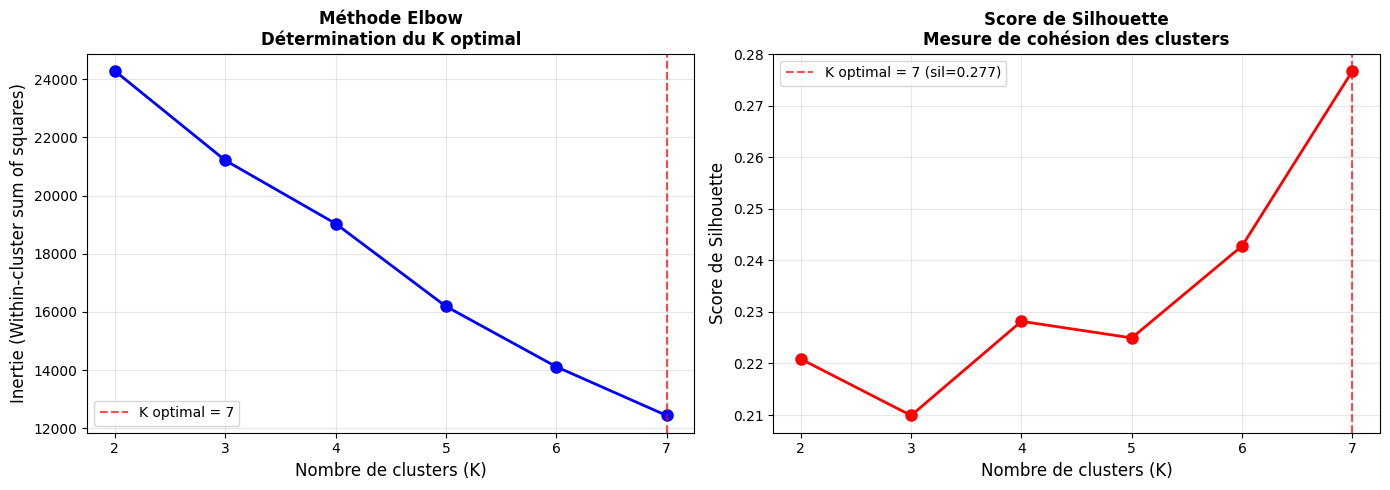

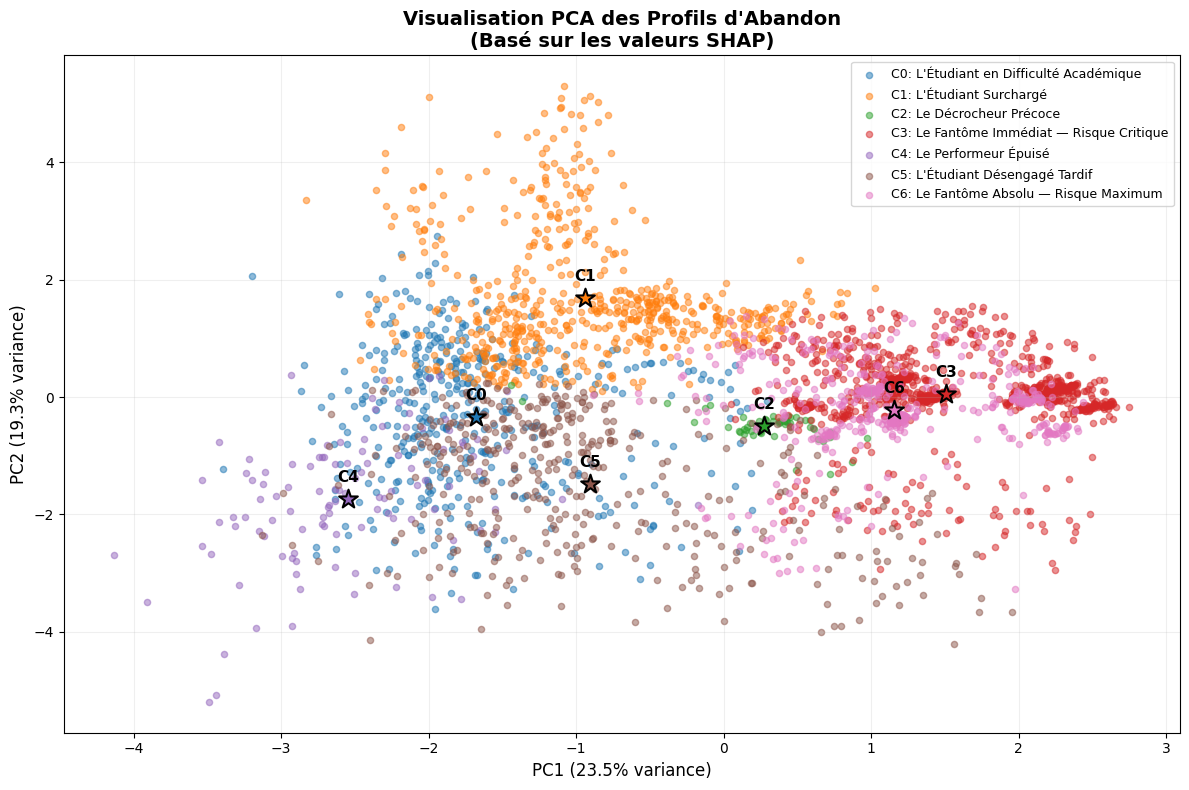

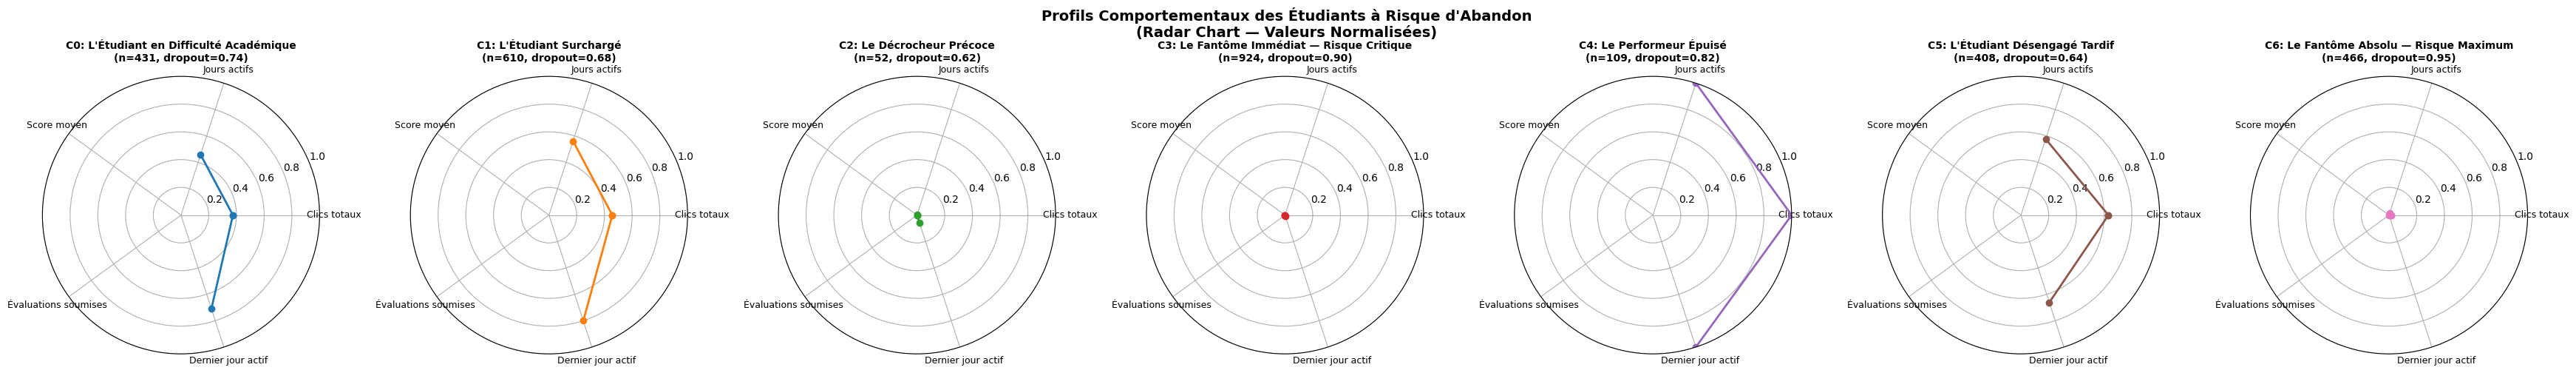

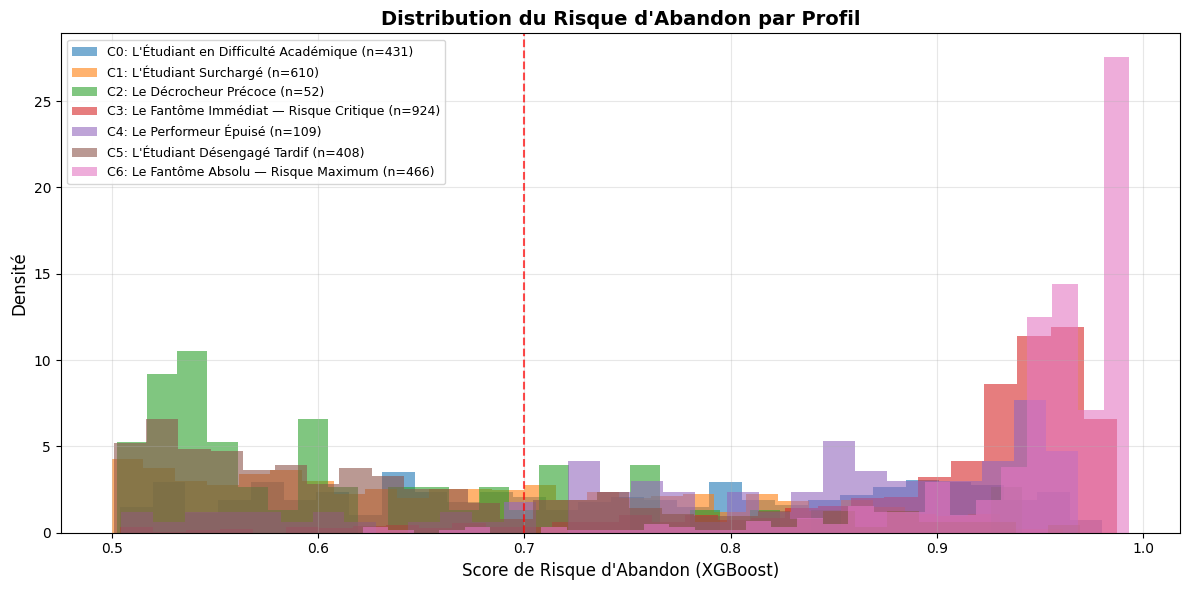

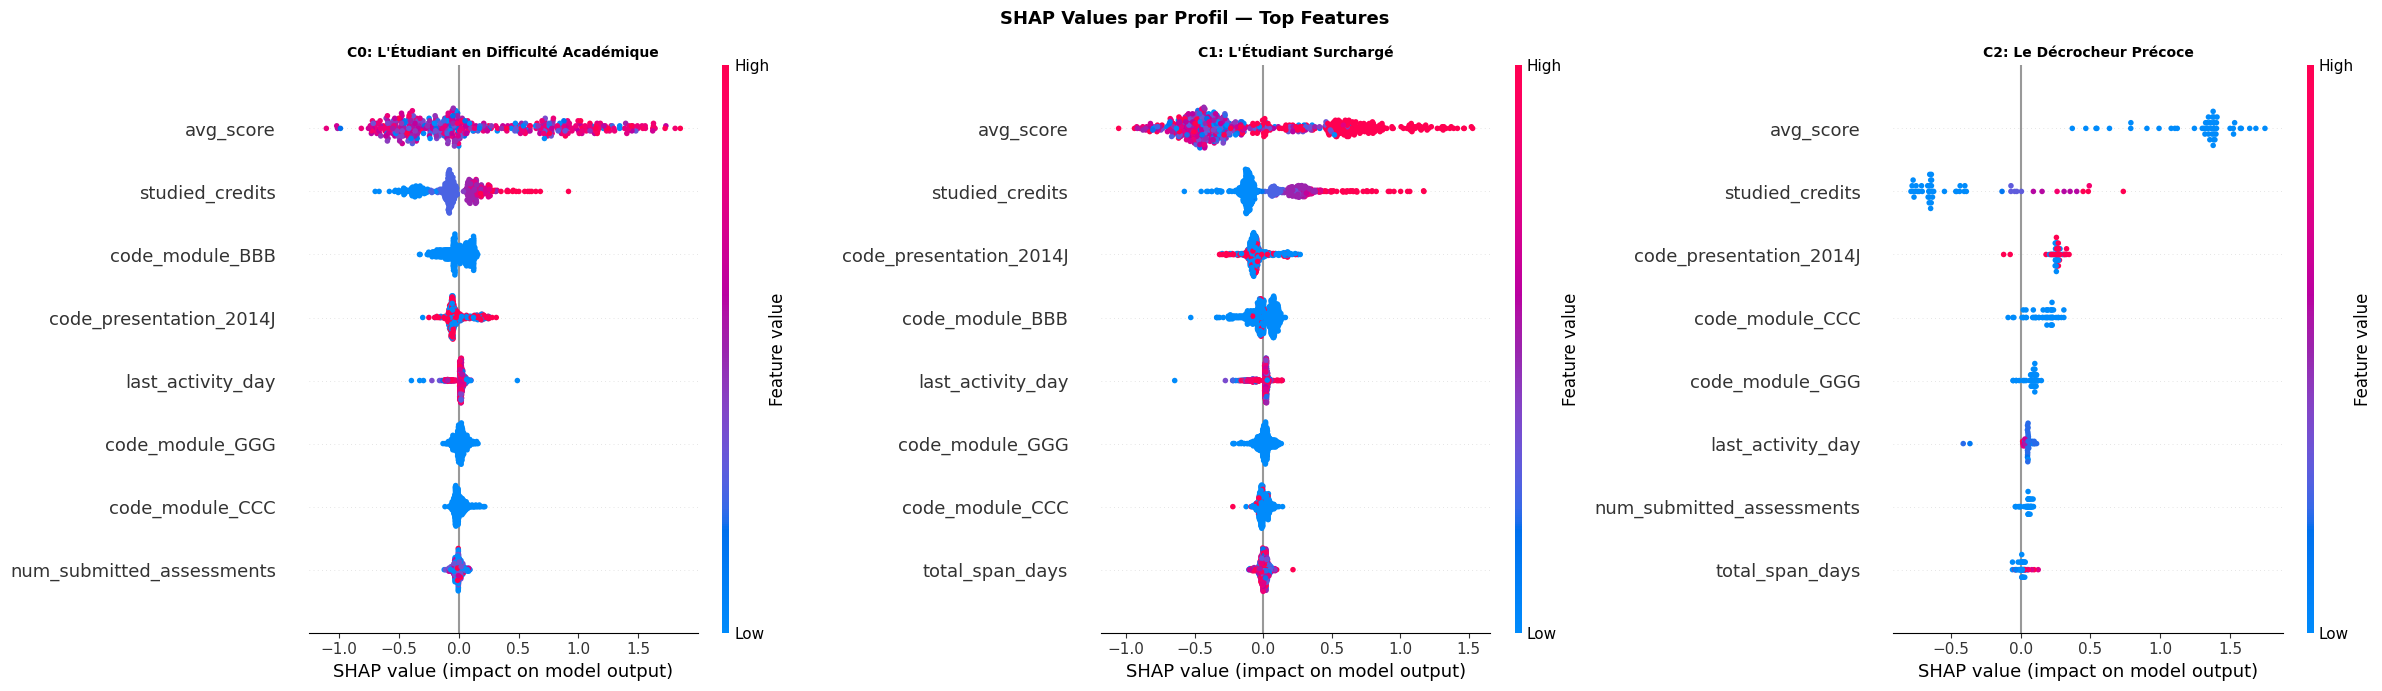

In [32]:
print("\n  Génération des visualisations...")

# ---- FIGURE 1 : Elbow + Silhouette ----
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(list(K_range), inertias, 'bo-', linewidth=2, markersize=8)
axes[0].axvline(best_k, color='red', linestyle='--', alpha=0.7,
                label=f'K optimal = {best_k}')
axes[0].set_xlabel('Nombre de clusters (K)', fontsize=12)
axes[0].set_ylabel('Inertie (Within-cluster sum of squares)', fontsize=12)
axes[0].set_title('Méthode Elbow\nDétermination du K optimal', fontweight='bold')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(list(K_range), silhouettes, 'ro-', linewidth=2, markersize=8)
axes[1].axvline(best_k, color='red', linestyle='--', alpha=0.7,
                label=f'K optimal = {best_k} (sil={max(silhouettes):.3f})')
axes[1].set_xlabel('Nombre de clusters (K)', fontsize=12)
axes[1].set_ylabel('Score de Silhouette', fontsize=12)
axes[1].set_title('Score de Silhouette\nMesure de cohésion des clusters', fontweight='bold')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f"{profiles_dir}/fig1_elbow_silhouette.png", dpi=300, bbox_inches='tight')
plt.show()

# ---- FIGURE 2 : PCA 2D des clusters ----
pca    = PCA(n_components=2, random_state=RANDOM_STATE)
coords = pca.fit_transform(shap_scaled)

fig, ax = plt.subplots(figsize=(12, 8))

for c in range(best_k):
    mask = cluster_labels == c
    ax.scatter(coords[mask, 0], coords[mask, 1],
               c=profile_colors[c], alpha=0.5, s=20,
               label=f'C{c}: {profile_names[c]}')

    # Centre du cluster
    cx, cy = coords[mask, 0].mean(), coords[mask, 1].mean()
    ax.scatter(cx, cy, c=profile_colors[c], s=200,
               marker='*', edgecolors='black', linewidth=1.5, zorder=5)
    ax.annotate(f'C{c}', (cx, cy), fontsize=11, fontweight='bold',
                ha='center', va='bottom',
                xytext=(0, 10), textcoords='offset points')

ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)', fontsize=12)
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)', fontsize=12)
ax.set_title('Visualisation PCA des Profils d\'Abandon\n(Basé sur les valeurs SHAP)',
             fontsize=14, fontweight='bold')
ax.legend(loc='upper right', fontsize=9)
ax.grid(True, alpha=0.2)

plt.tight_layout()
plt.savefig(f"{profiles_dir}/fig2_pca_clusters.png", dpi=300, bbox_inches='tight')
plt.show()

# ---- FIGURE 3 : Radar chart des profils ----
radar_features = ['total_clicks', 'total_days_active', 'avg_score',
                  'num_submitted_assessments', 'last_activity_day']
radar_labels   = ['Clics totaux', 'Jours actifs', 'Score moyen',
                  'Évaluations soumises', 'Dernier jour actif']

# Normaliser pour radar
radar_data = []
for c in range(best_k):
    row = df_cluster_stats[df_cluster_stats['cluster'] == c].iloc[0]
    vals = [row.get(f'{f}_mean', 0) for f in radar_features]
    radar_data.append(vals)

radar_array = np.array(radar_data)
radar_norm  = (radar_array - radar_array.min(0)) / \
              (radar_array.max(0) - radar_array.min(0) + 1e-9)

angles = np.linspace(0, 2*np.pi, len(radar_features), endpoint=False).tolist()
angles += angles[:1]

fig, axes = plt.subplots(1, best_k, figsize=(5*best_k, 5),
                         subplot_kw=dict(polar=True))
if best_k == 1:
    axes = [axes]

for c, ax in enumerate(axes):
    vals = radar_norm[c].tolist() + [radar_norm[c][0]]
    ax.plot(angles, vals, 'o-', linewidth=2, color=profile_colors[c])
    ax.fill(angles, vals, alpha=0.25, color=profile_colors[c])
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(radar_labels, size=9)
    ax.set_ylim(0, 1)
    ax.set_title(f'C{c}: {profile_names[c]}\n'
                 f'(n={int(df_cluster_stats.iloc[c]["n"])}, '
                 f'dropout={df_cluster_stats.iloc[c]["dropout_score_mean"]:.2f})',
                 size=10, fontweight='bold', pad=15)
    ax.grid(True)

plt.suptitle('Profils Comportementaux des Étudiants à Risque d\'Abandon\n(Radar Chart — Valeurs Normalisées)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{profiles_dir}/fig3_radar_profiles.png", dpi=300, bbox_inches='tight')
plt.show()

# ---- FIGURE 4 : Distribution dropout score par profil ----
fig, ax = plt.subplots(figsize=(12, 6))

for c in range(best_k):
    mask   = df_shap['cluster'] == c
    scores = df_shap[mask]['dropout_score'].values
    ax.hist(scores, bins=30, alpha=0.6, color=profile_colors[c],
            label=f'C{c}: {profile_names[c]} (n={mask.sum()})',
            density=True)

ax.set_xlabel('Score de Risque d\'Abandon (XGBoost)', fontsize=12)
ax.set_ylabel('Densité', fontsize=12)
ax.set_title('Distribution du Risque d\'Abandon par Profil',
             fontsize=14, fontweight='bold')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
ax.axvline(0.7, color='red', linestyle='--', alpha=0.7, label='Seuil risque élevé')

plt.tight_layout()
plt.savefig(f"{profiles_dir}/fig4_dropout_distribution_profiles.png",
            dpi=300, bbox_inches='tight')
plt.show()

# ---- FIGURE 5 : SHAP beeswarm par cluster ----
fig, axes = plt.subplots(1, min(best_k, 3), figsize=(8*min(best_k,3), 7))
if best_k == 1:
    axes = [axes]

for i, c in enumerate(range(min(best_k, 3))):
    mask     = cluster_labels == c
    if mask.sum() < 10:
        continue
    shap_c   = shap_values[mask][:, :10]
    X_c      = X_shap.iloc[mask]

    plt.sca(axes[i])
    shap.summary_plot(shap_c, X_c[top_features[:10]],
                      max_display=8, show=False,
                      plot_size=None)
    axes[i].set_title(f'C{c}: {profile_names[c]}',
                      fontsize=10, fontweight='bold')

plt.suptitle('SHAP Values par Profil — Top Features',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{profiles_dir}/fig5_shap_per_cluster.png",
            dpi=300, bbox_inches='tight')
plt.show()

# 10. TABLEAU FINAL DES PROFILS

In [33]:
print("\n" + "="*70)
print("  TABLEAU FINAL DES PROFILS D'ABANDON")
print("="*70)

print(f"\n  {'Cluster':<5} {'Nom':<35} {'N':<8} {'%':<8} "
      f"{'Dropout':<10} {'Clics':<10} {'Jours':<8} {'Score'}")
print("  " + "-"*95)

for _, row in df_cluster_stats.iterrows():
    c = int(row['cluster'])
    print(f"  C{c:<4} {profile_names[c]:<35} "
          f"{int(row['n']):<8} {row['pct']:<8.1f} "
          f"{row['dropout_score_mean']:<10.3f} "
          f"{row.get('total_clicks_mean',0):<10.1f} "
          f"{row.get('total_days_active_mean',0):<8.1f} "
          f"{row.get('avg_score_mean',0):.1f}")


  TABLEAU FINAL DES PROFILS D'ABANDON

  Cluster Nom                                 N        %        Dropout    Clics      Jours    Score
  -----------------------------------------------------------------------------------------------
  C0    L'Étudiant en Difficulté Académique 431      14.4     0.745      195.9      11.3     61.0
  C1    L'Étudiant Surchargé                610      20.3     0.677      235.1      13.6     46.7
  C2    Le Décrocheur Précoce               52       1.7      0.621      18.2       1.2      nan
  C3    Le Fantôme Immédiat — Risque Critique 924      30.8     0.903      17.5       1.0      65.2
  C4    Le Performeur Épuisé                109      3.6      0.815      493.9      23.4     74.0
  C5    L'Étudiant Désengagé Tardif         408      13.6     0.641      318.0      13.9     72.0
  C6    Le Fantôme Absolu — Risque Maximum  466      15.5     0.947      25.1       1.4      69.5


# 11. SAUVEGARDE

In [34]:
print("\n" + "="*70)
print("  SAUVEGARDE")
print("="*70)

import json

profiles_summary = {
    'best_k'          : int(best_k),
    'silhouette_score': float(max(silhouettes)),
    'n_risk_students' : int(len(df_shap)),
    'profiles'        : []
}

for _, row in df_cluster_stats.iterrows():
    c = int(row['cluster'])
    profiles_summary['profiles'].append({
        'cluster'           : c,
        'name'              : profile_names[c],
        'description'       : profile_descs[c],
        'n'                 : int(row['n']),
        'pct'               : float(row['pct']),
        'dropout_score_mean': float(row['dropout_score_mean']),
        'total_clicks_mean' : float(row.get('total_clicks_mean', 0)),
        'total_days_mean'   : float(row.get('total_days_active_mean', 0)),
        'avg_score_mean'    : float(row.get('avg_score_mean', 0)),
    })

with open(f"{profiles_dir}/profiles_summary.json", 'w') as f:
    json.dump(profiles_summary, f, indent=4, ensure_ascii=False)

df_shap[['cluster', 'dropout_score'] + key_features_orig].to_csv(
    f"{profiles_dir}/students_with_clusters.csv", index=False)

print("  Profils sauvegardés.")
print(f"\n  NOTEBOOK 06 TERMINÉ.")
print(f"  {best_k} profils identifiés avec Silhouette = {max(silhouettes):.4f}")
print(f"  Final")


  SAUVEGARDE
  Profils sauvegardés.

  NOTEBOOK 06 TERMINÉ.
  7 profils identifiés avec Silhouette = 0.2767
  Final
